<a href="https://colab.research.google.com/github/junelwc6-source/IBM-HR-Attrition-Analytics/blob/main/IBM_HR_Attrition_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Part 1 - Descriptive Analytics**


### 1. Project Overview

**Project Title:** Employee Attrition Analysis and Prediction

**Problem Statement:**

How can employee data be analysed to identify key factors associated with employee attrition, predict employees' likelihood of leaving, and support targeted retention strategies and proactive workforce planning to reduce attrition and minimise staffing gaps?

**Dataset:**

IBM HR Analytics Employee Attrition Dataset, comprising five datasets covering employee demographics, compensation, performance, work experience and employment status.



## 2. Load and check data quality

Load and examine the five IBM HR Analytics datasets, understand their structure and identify the variables available for employee attrition analysis.

datasets:

1. **Employees** – Employee demographics, department and job role.
2. **Compensation** – Salary and compensation information.
3. **Performance** – Job satisfaction, work-life balance and performance indicators.
4. **Experience** – Employment tenure, work experience and career progression.
5. **Employment Status** – Employee attrition and overtime status.



In [149]:

import pandas as pd

# GitHub repository location
base_url = "https://raw.githubusercontent.com/junelwc6-source/IBM-HR-Attrition-Analytics/main/"

# Load datasets directly from GitHub
employees = pd.read_csv(base_url + "Employees.csv")
compensation = pd.read_csv(base_url + "Compensation.csv")
performance = pd.read_csv(base_url + "Performance.csv")
experience = pd.read_csv(base_url + "Experience.csv")
employment_status = pd.read_csv(
    base_url + "Employment%20Status.csv"
)

# Check datasets loaded successfully
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", employment_status.shape)


Employees: (1470, 14)
Compensation: (1470, 7)
Performance: (1470, 7)
Experience: (1470, 8)
Employment Status: (1470, 3)


In [150]:

# Check data quality for all five datasets

datasets = {
    "Employees": employees,
    "Compensation": compensation,
    "Performance": performance,
    "Experience": experience,
    "Employment Status": employment_status
}

for name, df in datasets.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())



 Employees
Missing values: 5
Duplicate Employee IDs: 0

 Compensation
Missing values: 0
Duplicate Employee IDs: 0

 Performance
Missing values: 0
Duplicate Employee IDs: 0

 Experience
Missing values: 0
Duplicate Employee IDs: 0

 Employment Status
Missing values: 0
Duplicate Employee IDs: 0


**Key Observation**

All five datasets contain unique employee records, with no duplicate EmployeeNumbers identified. Five missing values were found in the Employees dataset, while the remaining four datasets had no missing values.

The missing values will be examined and handled in Section 3 — Data Preparation.


## 3. Data Preparation and Feature Engineering

## 3.1 Data Preparation

To clean and prepare the five datasets, address data quality issues, merge employee records into a single dataset, and create relevant features for descriptive and predictive analysis.

In [151]:

# Identify columns with missing values

print(employees.isnull().sum())

# Display records containing missing values
display(employees[employees.isnull().any(axis=1)])


EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [152]:
# Check the median age before cleaning
print("Median Age:", employees["Age"].median())

# Replace missing ages with the median age
employees["Age"] = employees["Age"].fillna(
    employees["Age"].median()
)

# Verify that no missing values remain
print("Missing Age values after cleaning:",
      employees["Age"].isnull().sum())

Median Age: 36.0
Missing Age values after cleaning: 0


Five employees had missing Age values. These were replaced with the median age of 36 to retain all 1,470 employee records for descriptive analysis.

The median was chosen because it is less affected by extreme values than the mean. After replacement, no missing Age values remained.

For predictive modelling, missing Age values will be handled separately within the model's preprocessing pipeline to prevent data leakage.

In [153]:

# Standardise gender values before data integration

employees["Gender"] = (
    employees["Gender"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "male",
        "f": "female",
        "femal": "female"
    })
    .str.title()
)

# Verify cleaned gender categories
print(employees["Gender"].value_counts())


Gender
Male      882
Female    588
Name: count, dtype: int64


In [154]:

# Check whether Employee IDs match across all datasets

employee_ids = set(employees["EmployeeNumber"])

for name, df in datasets.items():
    ids = set(df["EmployeeNumber"])

    print(name)
    print("IDs missing from this dataset:",
          len(employee_ids - ids))
    print("Extra IDs in this dataset:",
          len(ids - employee_ids))
    print()


Employees
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Compensation
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Performance
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Experience
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Employment Status
IDs missing from this dataset: 0
Extra IDs in this dataset: 0



In [155]:

# Merge the five IBM HR datasets into one master dataframe

df = employees.merge(compensation, on="EmployeeNumber", validate="one_to_one")

df = df.merge(performance, on="EmployeeNumber", validate="one_to_one")

df = df.merge(experience, on="EmployeeNumber", validate="one_to_one")

df = df.merge(employment_status, on="EmployeeNumber", validate="one_to_one")

# Check the merged dataset
print("Merged dataset shape:", df.shape)
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Display the first 5 rows
display(df.head())


Merged dataset shape: (1470, 35)
Duplicate Employee IDs: 0
Total missing values: 0


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,...,WorkLifeBalance,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,OverTime
0,1,41.0,Female,Single,2,Life Sciences,Sales,Sales Executive,2,Travel_Rarely,...,1,8,8,0,6,4,0,5,Yes,Yes
1,2,49.0,Male,Married,1,Life Sciences,Research & Development,Research Scientist,2,Travel_Frequently,...,3,1,10,3,10,7,1,7,No,No
2,4,37.0,Male,Single,2,Other,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,6,7,3,0,0,0,0,Yes,Yes
3,5,33.0,Female,Married,4,Life Sciences,Research & Development,Research Scientist,1,Travel_Frequently,...,3,1,8,3,8,7,3,0,No,Yes
4,7,27.0,Male,Married,1,Medical,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,9,6,3,2,2,2,2,No,No


The five datasets were validated using EmployeeNumber as the common identifier. All employee IDs matched across the datasets, allowing the records to be merged into a single dataset for analysis.

### 3.2 Feature Engineering

Create additional grouping variables to support employee attrition analysis and interactive reporting in Power BI.

In [156]:
# Create age groups for descriptive analysis and Power BI
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 29, 39, 49, float("inf")],
    labels=["Under 30", "30-39", "40-49", "50 and above"]
)

# Verify age group distribution
print(df["AgeGroup"].value_counts().sort_index())

AgeGroup
Under 30        325
30-39           624
40-49           348
50 and above    173
Name: count, dtype: int64


In [157]:

# Create monthly income groups within each department
income_labels = ["Low", "Lower-Middle", "Upper-Middle", "High"]

df["IncomeGroup"] = (
    df.groupby("Department")["MonthlyIncome"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=4,
            labels=income_labels
        )
    )
)

# Verify income group distribution
display(
    df.groupby(["Department", "IncomeGroup"], observed=True)
    .size()
    .reset_index(name="Employees")
)


,Department,IncomeGroup,Employees
0,Human Resources,Low,16
1,Human Resources,Lower-Middle,16
2,Human Resources,Upper-Middle,15
3,Human Resources,High,16
4,Research & Development,Low,241
5,Research & Development,Lower-Middle,240
6,Research & Development,Upper-Middle,240
7,Research & Development,High,240
8,Sales,Low,112
9,Sales,Lower-Middle,111


In [158]:

# Create total working experience groups
experience_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["ExperienceGroup"] = pd.cut(
    df["TotalWorkingYears"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=experience_labels
)

# Verify experience group distribution
print(df["ExperienceGroup"].value_counts().sort_index())


ExperienceGroup
0-2 years             123
3-5 years             193
6-10 years            607
11-20 years           340
More than 20 years    207
Name: count, dtype: int64


In [159]:

# Create groups based on years since last promotion
promotion_labels = [
    "0 years",
    "1-2 years",
    "3-5 years",
    "More than 5 years"
]

df["PromotionGroup"] = pd.cut(
    df["YearsSinceLastPromotion"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=promotion_labels
)

# Verify promotion group distribution
print(df["PromotionGroup"].value_counts().sort_index())


PromotionGroup
0 years              581
1-2 years            516
3-5 years            158
More than 5 years    215
Name: count, dtype: int64


In [160]:

# Create job satisfaction categories for Power BI
satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["SatisfactionGroup"] = df["JobSatisfaction"].map(
    satisfaction_labels
)

# Verify satisfaction categories
print(df["SatisfactionGroup"].value_counts())


SatisfactionGroup
Very High    459
High         442
Low          289
Medium       280
Name: count, dtype: int64


In [161]:

# Create work-life balance categories for Power BI
wlb_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

df["WorkLifeBalanceGroup"] = df["WorkLifeBalance"].map(wlb_labels)

# Verify work-life balance categories
print(df["WorkLifeBalanceGroup"].value_counts().sort_index())


WorkLifeBalanceGroup
Bad        80
Best      153
Better    893
Good      344
Name: count, dtype: int64


In [162]:

# Create distance-from-home groups for Power BI
distance_labels = [
    "1-5",
    "6-10",
    "11-20",
    "More than 20"
]

df["DistanceGroup"] = pd.cut(
    df["DistanceFromHome"],
    bins=[0, 5, 10, 20, float("inf")],
    labels=distance_labels
)

# Verify distance group distribution
print(df["DistanceGroup"].value_counts().sort_index())

# Check for unassigned employees
print("Unassigned records:", df["DistanceGroup"].isna().sum())


DistanceGroup
1-5             632
6-10            394
11-20           240
More than 20    204
Name: count, dtype: int64
Unassigned records: 0


In [163]:

# Create company tenure groups for Power BI
tenure_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=tenure_labels
)

# Verify tenure group distribution
print(df["TenureGroup"].value_counts().sort_index())

# Check for unassigned employees
print("Unassigned records:", df["TenureGroup"].isna().sum())


TenureGroup
0-2 years             342
3-5 years             434
6-10 years            448
11-20 years           180
More than 20 years     66
Name: count, dtype: int64
Unassigned records: 0


In [164]:

# Create environment satisfaction categories for Power BI
environment_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["EnvironmentSatisfactionGroup"] = (
    df["EnvironmentSatisfaction"].map(environment_labels)
)

# Verify environment satisfaction categories
print(df["EnvironmentSatisfactionGroup"].value_counts().sort_index())

# Check for unassigned records
print("Unassigned records:", df["EnvironmentSatisfactionGroup"].isna().sum())


EnvironmentSatisfactionGroup
High         453
Low          284
Medium       287
Very High    446
Name: count, dtype: int64
Unassigned records: 0


In [165]:

# Create relationship satisfaction categories for Power BI
relationship_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["RelationshipSatisfactionGroup"] = (
    df["RelationshipSatisfaction"].map(relationship_labels)
)

# Verify relationship satisfaction categories
print(df["RelationshipSatisfactionGroup"].value_counts().sort_index())

# Check for unassigned records
print("Unassigned records:",
      df["RelationshipSatisfactionGroup"].isna().sum())


RelationshipSatisfactionGroup
High         459
Low          276
Medium       303
Very High    432
Name: count, dtype: int64
Unassigned records: 0


In [166]:

# Validate feature engineering results
group_columns = [
    "AgeGroup", "IncomeGroup", "ExperienceGroup",
    "PromotionGroup", "SatisfactionGroup",
    "WorkLifeBalanceGroup", "DistanceGroup",
    "TenureGroup", "EnvironmentSatisfactionGroup",
    "RelationshipSatisfactionGroup"
]

print("Total employees:", len(df))
print("Grouping variables created:", len(group_columns))
print("\nMissing values in grouping variables:")
print(df[group_columns].isnull().sum())


Total employees: 1470
Grouping variables created: 10

Missing values in grouping variables:
AgeGroup                         0
IncomeGroup                      0
ExperienceGroup                  0
PromotionGroup                   0
SatisfactionGroup                0
WorkLifeBalanceGroup             0
DistanceGroup                    0
TenureGroup                      0
EnvironmentSatisfactionGroup     0
RelationshipSatisfactionGroup    0
dtype: int64


### Summary

The five datasets were successfully cleaned and merged into a single dataset containing 1,470 employee records.

Ten additional grouping variables were created to support descriptive analysis and interactive reporting in Power BI. All employees were successfully categorised, with no missing values in the newly created variables.

The original employee attributes have been retained for predictive modelling.

## 4. Descriptive and Diagnostic Analysis

### Objective 1 — Analyse overall employee attrition patterns, departmental differences and the relationship between overtime and attrition.

**Sections covered:** 4.1–4.3

### 4.1 Overall Employee Attrition

In [167]:

# Calculate overall employee attrition

total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = (df["Attrition"] == "No").sum()

overall_attrition_rate = (
    employees_left / total_employees * 100
)

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")


Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Overall Attrition Rate: 16.12%



### Key Findings

The dataset contains 1,470 employees, of whom 237 (16.12%) left the organisation, while 1,233 (83.88%) remained.

The overall attrition rate of 16.12% provides a baseline for identifying departments and employee groups with higher attrition rates.

Further analysis will examine the factors associated with employee attrition and identify opportunities for targeted retention strategies.

### 4.2 Departmental Attrition Analysis

In [168]:

# Calculate employee attrition by department

department_attrition = (
    df.groupby("Department")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

department_attrition["Attrition_Rate"] = (
    department_attrition["Employees_Left"] /
    department_attrition["Total_Employees"] * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(department_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


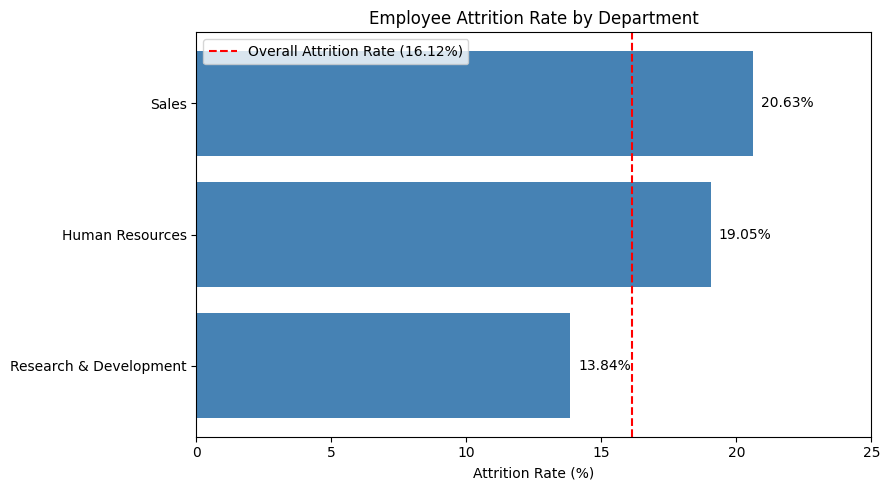

In [169]:

# Visualise attrition rates by department

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

bars = plt.barh(
    department_attrition.index,
    department_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add attrition rate labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Overall attrition rate as benchmark
plt.axvline(
    overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.xlim(0, 25)
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()



### Key Findings

Sales recorded the highest attrition rate at 20.63% (92 out of 446 employees), followed by Human Resources at 19.05% (12 out of 63 employees). Both departments exceeded the overall attrition rate of 16.12%.

Research & Development recorded the lowest attrition rate at 13.84%. However, it had the highest number of employees who left (133), reflecting its larger workforce.

These findings indicate that Sales and Human Resources have higher relative attrition rates, while Research & Development contributes the largest number of employee departures.

Further analysis will examine the factors associated with attrition within each department to identify potential areas for targeted retention strategies.

### 4.3 Overtime and Employee Attrition

In [170]:

# Calculate attrition by department and overtime
overtime_attrition = (
    df.groupby(["Department", "OverTime"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Employees_Left"] /
    overtime_attrition["Total_Employees"] * 100
).round(2)

# Arrange results by department and overtime status
overtime_attrition = overtime_attrition.sort_values(
    ["Department", "OverTime"]
)

display(overtime_attrition)


,Department,OverTime,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,No,46,7,15.22
1,Human Resources,Yes,17,5,29.41
2,Research & Development,No,690,59,8.55
3,Research & Development,Yes,271,74,27.31
4,Sales,No,318,44,13.84
5,Sales,Yes,128,48,37.50


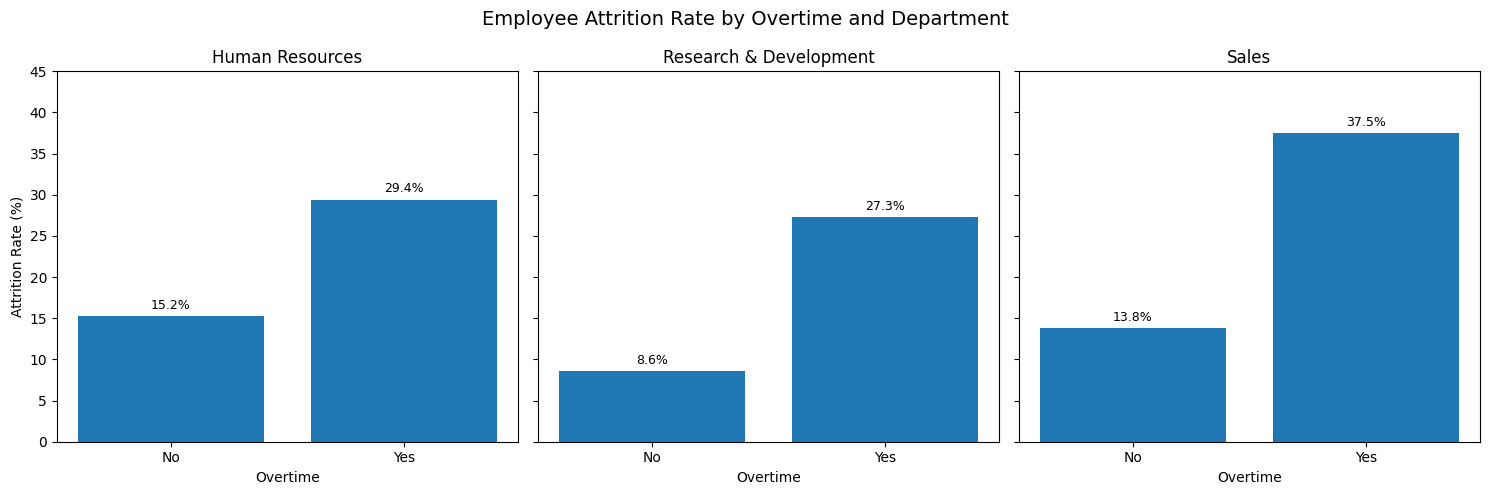

In [171]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        overtime_attrition[
            overtime_attrition["Department"] == dept
        ]
        .set_index("OverTime")
        .reindex(["No", "Yes"])
    )

    bars = ax.bar(
        ["No", "Yes"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Overtime")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Overtime and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees working overtime recorded an attrition rate of 29.41%, compared with 15.22% among those not working overtime.
- **Research & Development:** Employees working overtime had an attrition rate of 27.31%, compared with 8.55% among those not working overtime.
- **Sales:** Employees working overtime recorded the highest attrition rate at 37.50%, compared with 13.84% among those not working overtime.
- **Overall:** Overtime was consistently associated with higher attrition across all three departments, with the largest percentage-point difference observed in Sales. This suggests that workload management and overtime practices should be prioritised for further investigation when developing employee retention strategies.

*Note: These findings show an association between overtime and attrition, but do not establish that overtime causes employees to leave.*

## **Part 2 - Predictive Analystics**

## 5. Predictive Employee Attrition Modelling

### Objective 2 — Develop and compare machine learning models to predict employee attrition.

**Sections covered:** 5.1–5.5

### 5.1 Predictor Selection

In [172]:

# Section 5.1 - Select predictors for attrition modelling

predictor_columns = [
    "Department",
    "JobRole",
    "JobLevel",
    "BusinessTravel",
    "DistanceFromHome",
    "MonthlyIncome",
    "PercentSalaryHike",
    "StockOptionLevel",
    "PerformanceRating",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance",
    "NumCompaniesWorked",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
    "OverTime"
]

target_column = "Attrition"

# Create modelling dataset
model_df = df[predictor_columns + [target_column]].copy()

# Validate modelling dataset
print("Modelling dataset shape:", model_df.shape)
print("Missing values:", model_df.isnull().sum().sum())

print("\nAttrition distribution:")
print(model_df["Attrition"].value_counts())


Modelling dataset shape: (1470, 23)
Missing values: 0

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


A total of 22 workplace, compensation and career-related variables were selected as candidate predictors. Demographic characteristics, administrative fields and grouping variables created for Power BI were excluded.

The predictive contribution of these variables will be evaluated during model development.

### 5.2 Training and Testing Data

In [173]:

# Section 5.2 - Prepare data and split into training and testing sets

from sklearn.model_selection import train_test_split

# Separate predictors and target
X = model_df[predictor_columns].copy()
y = model_df["Attrition"].map({"No": 0, "Yes": 1})

# Split data: 80% training and 20% testing
# Stratify to preserve the attrition proportion
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify the split
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining attrition distribution:")
print(y_train.value_counts())

print("\nTesting attrition distribution:")
print(y_test.value_counts())


Training records: 1176
Testing records: 294

Training attrition distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing attrition distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


The dataset was divided into 80% training data (1,176 employees) and 20% testing data (294 employees).

Stratified sampling was applied to maintain a similar proportion of employees who left the organisation in both datasets. The training data will be used for model development, while the testing data will be reserved for final evaluation.

### 5.3 Data Preprocessing

To prepare numerical and categorical variables for predictive modelling.

In [174]:

# Section 5.3 - Data preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical predictors
categorical_features = [
    "Department",
    "JobRole",
    "BusinessTravel",
    "OverTime"
]

numerical_features = [
    col for col in predictor_columns
    if col not in categorical_features
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Verify preprocessing configuration
print("Preprocessing pipeline created successfully.")
print("Numerical predictors:", len(numerical_features))
print("Categorical predictors:", len(categorical_features))
print("Total predictors:", len(predictor_columns))


Preprocessing pipeline created successfully.
Numerical predictors: 18
Categorical predictors: 4
Total predictors: 22


The 22 selected predictors consist of 18 numerical and 4 categorical variables.

- **Numerical variables:** Missing values are handled using median imputation, followed by standardisation.
- **Categorical variables:** Missing values are handled using the most frequent category, followed by one-hot encoding.

A preprocessing pipeline is used to ensure that transformations are fitted on the training data, reducing the risk of data leakage.

### 5.4 Model Development

To develop and compare classification models for predicting employee attrition.

Two models will be evaluated:

1. Logistic Regression — An interpretable model used to establish baseline predictive performance.
2. Random Forest — A model capable of identifying more complex relationships between employee and workplace factors.

Both models will use the same preprocessing pipeline and training dataset. Cross-validation will be used to compare model performance before final testing.

In [175]:

# Section 5.4.1 - Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print("Training records:", len(X_train))


Logistic Regression model trained successfully.
Training records: 1176


In [176]:

# Section 5.4.2 - Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data only
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print("Training records:", len(X_train))


Random Forest model trained successfully.
Training records: 1176


### 5.5 Model Comparison Using Cross-Validation

To compare the predictive performance of Logistic Regression and Random Forest using training data.

Five-fold stratified cross-validation is used to evaluate both models while maintaining a similar proportion of employees who left in each fold.

The models will be compared using ROC-AUC, recall and F1-score. These metrics help assess how well the models distinguish employees who may leave and identify potential attrition cases.

The test dataset remains reserved for final model evaluation.

In [177]:

# Section 5.5 - Compare models using 5-fold cross-validation

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models to compare
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# Evaluation metrics
scoring = {
    "ROC-AUC": "roc_auc",
    "Recall": "recall",
    "F1-Score": "f1"
}

# Evaluate models using training data only
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_ROC-AUC"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-Score": scores["test_F1-Score"].mean()
    })

# Display comparison
cv_results = pd.DataFrame(results)
display(cv_results.round(3))


,Model,ROC-AUC,Recall,F1-Score
0,Logistic Regression,0.831,0.753,0.495
1,Random Forest,0.808,0.463,0.496


#### Key Findings

Logistic Regression achieved a higher ROC-AUC (0.831) and recall (0.753) than Random Forest (0.808 and 0.463 respectively).

Both models recorded similar F1-scores of approximately 0.50.

Based on the cross-validation results, Logistic Regression was selected for further evaluation because of its stronger ability to identify employees who may leave the organisation.

The selected model will be evaluated using the held-out test dataset to assess its performance on unseen data.

### Model Evaluation and Predictor Importance

#### Objective 3 — Evaluate the selected predictive model, assess probability calibration and identify important attrition predictors.

**Sections covered:** 5.6–5.8

In [178]:

# Section 5.6 - Final evaluation of Logistic Regression

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate predictions on unseen testing data
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
final_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_logistic, zero_division=0),
        recall_score(y_test, y_pred_logistic, zero_division=0),
        f1_score(y_test, y_pred_logistic, zero_division=0),
        roc_auc_score(y_test, y_prob_logistic)
    ]
})

print("Logistic Regression - Final Test Performance")
display(final_results.round(3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Stayed", "Left"],
    zero_division=0
))



Logistic Regression - Final Test Performance


,Metric,Score
0,Accuracy,0.759
1,Precision,0.370
2,Recall,0.723
3,F1-Score,0.489
4,ROC-AUC,0.795



Confusion Matrix:
[[189  58]
 [ 13  34]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.94      0.77      0.84       247
        Left       0.37      0.72      0.49        47

    accuracy                           0.76       294
   macro avg       0.65      0.74      0.67       294
weighted avg       0.85      0.76      0.79       294



#### Key Findings

The Logistic Regression model achieved an accuracy of 75.9%, recall of 72.3% and ROC-AUC of 0.795 on the test dataset.

Of the 47 employees who left, the model correctly identified 34 and missed 13. However, it also incorrectly predicted attrition for 58 employees who stayed, resulting in a precision of 37.0%.

The results indicate that the model can identify a substantial proportion of potential attrition cases, although false-positive predictions remain a limitation.

The model may support early identification of employee attrition risk, but predictions should be used as indicators for further HR review rather than definitive assessments or automatic employment decisions.

In [179]:

# Section 5.7 - Assess probability calibration

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.base import clone

# Use training data only for calibration assessment
calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold predicted probabilities
train_prob = cross_val_predict(
    clone(logistic_model),
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate calibration metrics
brier_score = brier_score_loss(y_train, train_prob)
roc_auc = roc_auc_score(y_train, train_prob)

print("Logistic Regression - Probability Assessment")
print(f"Brier Score: {brier_score:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

print(f"\nActual attrition rate: {y_train.mean():.2%}")
print(f"Average predicted attrition probability: {train_prob.mean():.2%}")

# Compare predicted probabilities with observed attrition
calibration_df = pd.DataFrame({
    "Actual_Attrition": y_train.to_numpy(),
    "Predicted_Probability": train_prob
})

calibration_df["Probability_Group"] = pd.qcut(
    calibration_df["Predicted_Probability"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

calibration_summary = (
    calibration_df.groupby("Probability_Group", observed=True)
    .agg(
        Employees=("Actual_Attrition", "count"),
        Average_Predicted=("Predicted_Probability", "mean"),
        Actual_Attrition_Rate=("Actual_Attrition", "mean")
    )
    .reset_index()
)

display(calibration_summary.round(3))


Logistic Regression - Probability Assessment
Brier Score: 0.160
ROC-AUC: 0.829

Actual attrition rate: 16.16%
Average predicted attrition probability: 36.60%


,Probability_Group,Employees,Average_Predicted,Actual_Attrition_Rate
0,Q1,236,0.040,0.034
1,Q2,235,0.144,0.051
2,Q3,235,0.310,0.077
3,Q4,235,0.538,0.140
4,Q5,235,0.800,0.506


In [180]:

# Section 5.7 - Fit calibrated Logistic Regression model

from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Fit the calibrated model using training data only
calibrated_logistic_model = CalibratedClassifierCV(
    estimator=clone(logistic_model),
    method="sigmoid",
    cv=calibration_cv
)

calibrated_logistic_model.fit(X_train, y_train)

# Generate out-of-fold calibrated training probabilities
calibrated_train_prob = cross_val_predict(
    CalibratedClassifierCV(
        estimator=clone(logistic_model),
        method="sigmoid",
        cv=calibration_cv
    ),
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Calibrated Logistic Regression model created successfully.")


Calibrated Logistic Regression model created successfully.


In [181]:
# Section 5.7 - Test calibrated model on unseen data

test_prob_original = logistic_model.predict_proba(X_test)[:, 1]
test_prob_calibrated = calibrated_logistic_model.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame({
    "Measure": ["Brier Score", "ROC-AUC", "Average Predicted Probability"],
    "Original": [
        brier_score_loss(y_test, test_prob_original),
        roc_auc_score(y_test, test_prob_original),
        test_prob_original.mean()
    ],
    "Calibrated": [
        brier_score_loss(y_test, test_prob_calibrated),
        roc_auc_score(y_test, test_prob_calibrated),
        test_prob_calibrated.mean()
    ]
})

display(test_results.round(3))
print(f"Actual Test Attrition Rate: {y_test.mean():.2%}")

,Measure,Original,Calibrated
0,Brier Score,0.162,0.100
1,ROC-AUC,0.795,0.795
2,Average Predicted Probability,0.358,0.156


Actual Test Attrition Rate: 15.99%


#### Key Findings

Probability calibration improved the Logistic Regression model's Brier Score from 0.160 to 0.098 during cross-validation.

The improvement was also confirmed on the unseen test dataset, where the Brier Score decreased from 0.162 to 0.100. The average predicted attrition probability (15.6%) was close to the actual test attrition rate (15.99%).

ROC-AUC remained relatively stable at 0.794 after calibration, indicating that the model maintained its ability to distinguish employees who left from those who stayed.

These findings support using the calibrated Logistic Regression model for subsequent employee attrition risk analysis in Section 6.

*Note: Predicted probabilities are estimates and should not be interpreted as certain employee departures.*

Predictor Importance Ranking:


,Predictor,Importance
15,TotalWorkingYears,0.0789
21,OverTime,0.0666
1,JobRole,0.0477
3,BusinessTravel,0.0233
7,StockOptionLevel,0.0232
11,JobSatisfaction,0.0191
19,YearsSinceLastPromotion,0.0181
20,YearsWithCurrManager,0.0180
5,MonthlyIncome,0.0161
10,JobInvolvement,0.0160


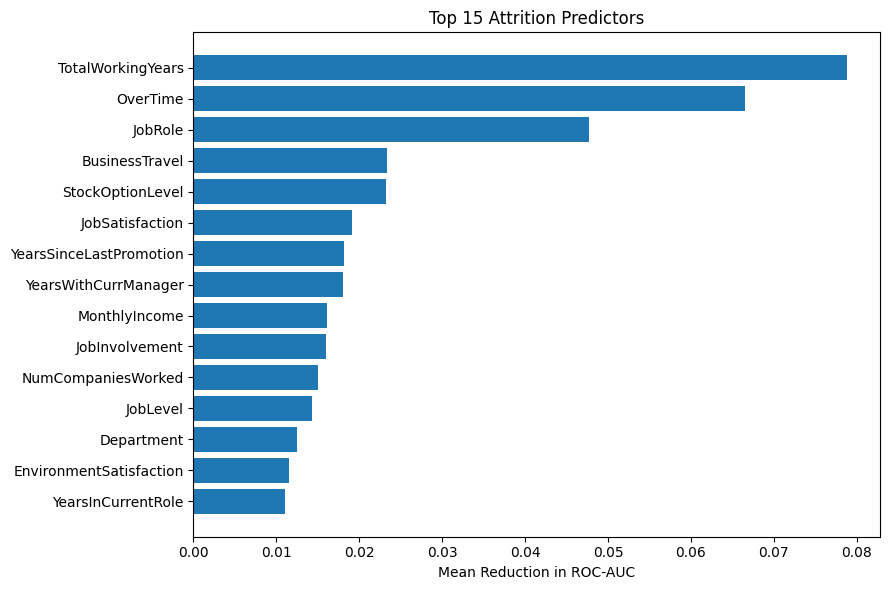

In [182]:

# Section 5.8 - Predictor importance using cross-validation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

# Define 5-fold cross-validation
cv_importance = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for train_idx, val_idx in cv_importance.split(X_train, y_train):

    # Train a fresh calibrated model for each fold
    model = clone(calibrated_logistic_model)

    model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    # Calculate importance on unseen validation data
    importance = permutation_importance(
        model,
        X_train.iloc[val_idx],
        y_train.iloc[val_idx],
        scoring="roc_auc",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(importance.importances_mean)

# Average importance across validation folds
importance_df = pd.DataFrame({
    "Predictor": predictor_columns,
    "Importance": pd.DataFrame(importance_results).mean(axis=0)
}).sort_values("Importance", ascending=False)

# Display all 22 predictors
print("Predictor Importance Ranking:")
display(importance_df.round(4))

# Visualise the 15 most important predictors
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Predictor"],
    top_features["Importance"]
)

plt.xlabel("Mean Reduction in ROC-AUC")
plt.title("Top 15 Attrition Predictors")
plt.tight_layout()
plt.show()


#### Key Findings

Permutation importance identified **Total Working Years (0.0769), Overtime (0.0655) and Job Role (0.0481)** as the three most influential predictors in the calibrated Logistic Regression model.

Other important predictors included Business Travel, Stock Option Level, Monthly Income, Job Satisfaction and Years with Current Manager.

These findings suggest that work experience, workload, job responsibilities, compensation and employee satisfaction are relevant areas for further HR investigation.

The results will guide the subsequent employee attrition risk analysis and support the development of targeted retention recommendations.

*Note: Predictor importance reflects the model's reliance on each variable and does not establish causation or indicate whether higher values increase or decrease attrition risk.*

## 6. Employee Attrition Risk Assessment

### Objective 4 — Assess predicted employee attrition risk and identify higher-risk employee groups across departments.

**Sections covered:** 6.1–6.6

Predicted Attrition Probability Summary:


,Probability
count,294.000
mean,0.156
std,0.175
min,0.002
25%,0.036
50%,0.088
75%,0.215
max,0.904


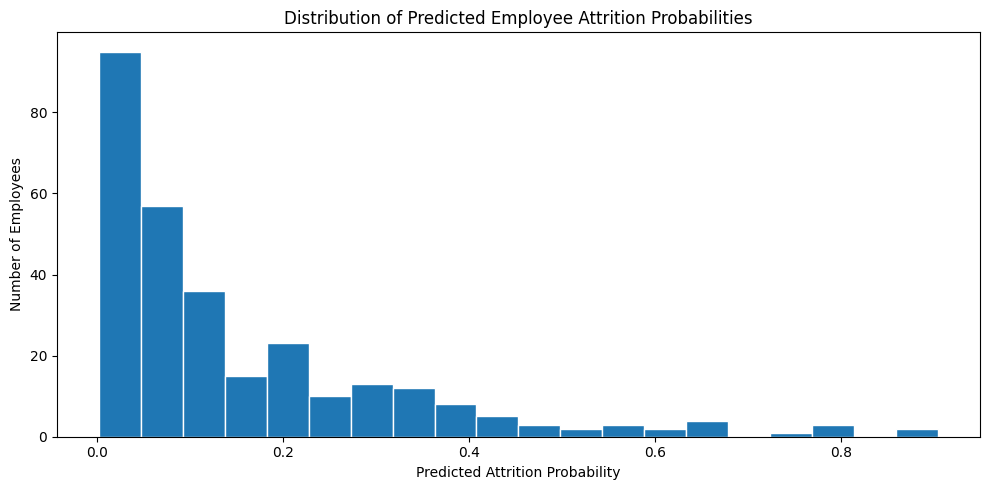

In [183]:

# Section 6.1 - Examine predicted attrition probabilities

import pandas as pd
import matplotlib.pyplot as plt

# Generate calibrated probabilities for the test dataset
y_prob_calibrated = calibrated_logistic_model.predict_proba(X_test)[:, 1]

# Create test dataset containing predictions
risk_df = X_test.copy()

risk_df["EmployeeNumber"] = df.loc[X_test.index, "EmployeeNumber"]
risk_df["Actual_Attrition"] = y_test
risk_df["Predicted_Probability"] = y_prob_calibrated

# Display probability summary
print("Predicted Attrition Probability Summary:")
display(
    risk_df["Predicted_Probability"]
    .describe()
    .round(3)
    .to_frame("Probability")
)

# Visualise probability distribution
plt.figure(figsize=(10, 5))
plt.hist(
    risk_df["Predicted_Probability"],
    bins=20,
    edgecolor="white"
)

plt.title("Distribution of Predicted Employee Attrition Probabilities")
plt.xlabel("Predicted Attrition Probability")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


#### Key Findings

The calibrated Logistic Regression model generated predicted attrition probabilities for **294 employees in the test dataset**.

- The average predicted attrition probability was **15.6%**, close to the actual test attrition rate of 15.99%.
- The median predicted probability was **8.6%**, indicating that half of the employees had predicted attrition probabilities below this level.
- Predicted probabilities ranged from **0.3% to 87.9%**, showing considerable variation in estimated attrition risk.
- The distribution was right-skewed, with most employees having relatively low predicted probabilities and a smaller group showing higher estimated risk.

These findings support the next stage of analysis, where employees will be grouped into risk categories to identify potential areas for HR investigation.

*Note: Predicted probabilities represent estimated attrition risk, not confirmed future departures.*

In [184]:

# Section 6.2 - Employee attrition risk segmentation

import numpy as np
import pandas as pd

# Calculate risk thresholds from training data only
low_threshold = np.quantile(calibrated_train_prob, 0.50)
high_threshold = np.quantile(calibrated_train_prob, 0.80)

print(f"Low / Medium threshold: {low_threshold:.2%}")
print(f"Medium / High threshold: {high_threshold:.2%}")

# Apply training-derived thresholds to test predictions
risk_df["Risk_Level"] = pd.cut(
    risk_df["Predicted_Probability"],
    bins=[-np.inf, low_threshold, high_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

# Summarise risk groups
risk_summary = (
    risk_df.groupby("Risk_Level", observed=True)
    .agg(
        Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Average_Predicted_Probability=("Predicted_Probability", "mean")
    )
    .reset_index()
)

risk_summary["Actual_Attrition_Rate"] = (
    risk_summary["Employees_Left"] /
    risk_summary["Employees"] * 100
)

risk_summary["Average_Predicted_Probability"] = (
    risk_summary["Average_Predicted_Probability"] * 100
)

display(risk_summary.round(2))

print("\nTotal employees:", risk_summary["Employees"].sum())


Low / Medium threshold: 9.80%
Medium / High threshold: 27.12%


,Risk_Level,Employees,Employees_Left,Average_Predicted_Probability,Actual_Attrition_Rate
0,Low,161,12,4.33,7.45
1,Medium,75,7,16.90,9.33
2,High,58,28,45.03,48.28



Total employees: 294


#### Key Findings

Employees were classified into Low, Medium and High attrition risk groups using thresholds derived from the training dataset:

- **Low Risk:** Predicted probability up to 9.87%.
- **Medium Risk:** Predicted probability above 9.87% and up to 26.74%.
- **High Risk:** Predicted probability above 26.74%.

Of the 294 test employees:

- **163 employees** were classified as Low Risk, with 12 actual departures (7.36%).
- **70 employees** were classified as Medium Risk, with 5 actual departures (7.14%).
- **61 employees** were classified as High Risk, with 30 actual departures (49.18%).

The High Risk group accounted for **30 of the 47 actual departures (63.8%)**, demonstrating that the model identified a substantial proportion of employees who left.

The model distinguished the High Risk group more clearly than the Low and Medium Risk groups, which had similar observed attrition rates.

These findings provide a basis for examining risk patterns across departments and employee characteristics.

*Note: Risk categories are relative classifications based on the training data and do not guarantee whether an employee will leave.*

In [185]:

# Section 6.3 - Departmental attrition risk analysis

import pandas as pd

# Calculate employee counts by department and risk level
department_risk = (
    risk_df.groupby(
        ["Department", "Risk_Level"],
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum")
    )
    .reset_index()
)

# Calculate total employees in each department
department_totals = (
    risk_df.groupby("Department")
    .size()
    .rename("Department_Total")
    .reset_index()
)

# Add department totals
department_risk = department_risk.merge(
    department_totals,
    on="Department",
    how="left"
)

# Calculate percentage of department employees in each risk level
department_risk["Percentage_of_Department"] = (
    department_risk["Total_Employees"] /
    department_risk["Department_Total"] * 100
).round(2)

# Calculate actual attrition rate within each risk level
department_risk["Observed_Attrition_Rate"] = (
    department_risk["Employees_Left"] /
    department_risk["Total_Employees"] * 100
).round(2)

# Arrange results
department_risk = department_risk[
    [
        "Department",
        "Risk_Level",
        "Total_Employees",
        "Employees_Left",
        "Percentage_of_Department",
        "Observed_Attrition_Rate"
    ]
]

print("Departmental Employee Attrition Risk Distribution:")
display(department_risk)


Departmental Employee Attrition Risk Distribution:


,Department,Risk_Level,Total_Employees,Employees_Left,Percentage_of_Department,Observed_Attrition_Rate
0,Human Resources,Low,8,0,53.33,0.00
1,Human Resources,Medium,4,1,26.67,25.00
2,Human Resources,High,3,1,20.00,33.33
3,Research & Development,Low,118,12,59.90,10.17
4,Research & Development,Medium,54,5,27.41,9.26
5,Research & Development,High,25,12,12.69,48.00
6,Sales,Low,35,0,42.68,0.00
7,Sales,Medium,17,1,20.73,5.88
8,Sales,High,30,15,36.59,50.00


#### Key Findings

Sales recorded the highest proportion of High Risk employees at 37.80% (31 of 82 employees), followed by Human Resources at 20.00% (3 of 15 employees) and Research & Development at 13.71% (27 of 197 employees).

Among High Risk employees, the observed attrition rate was 48.39% in Sales and 51.85% in Research & Development.

Although Research & Development had a lower proportion of High Risk employees, 14 employees in this group left, compared with 15 in Sales.

Human Resources had a small test sample of 15 employees, so its results should be interpreted cautiously.

These findings highlight departmental differences in predicted attrition risk and provide a basis for further investigation into workplace and career-related factors.

In [186]:

# Section 6.4 - High Risk Employee Profile Analysis

import pandas as pd

# Select employees classified as High Risk
high_risk_df = risk_df[
    risk_df["Risk_Level"] == "High"
].copy()

# Calculate high-risk employee profiles by department
high_risk_profile = (
    high_risk_df.groupby("Department")
    .agg(
        High_Risk_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean"),
        Average_Years_Since_Promotion=("YearsSinceLastPromotion", "mean"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

# Calculate overtime percentage
high_risk_profile["Overtime_Percentage"] = (
    high_risk_profile["Overtime_Employees"] /
    high_risk_profile["High_Risk_Employees"] * 100
)

# Convert predicted risk to percentage
high_risk_profile["Average_Predicted_Risk"] *= 100

# Round values
high_risk_profile = high_risk_profile.round(2)

print("High Risk Employee Profiles by Department:")
display(high_risk_profile)


High Risk Employee Profiles by Department:


,Department,High_Risk_Employees,Employees_Left,Overtime_Employees,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years,Average_Years_Since_Promotion,Average_Predicted_Risk,Overtime_Percentage
0,Human Resources,3,1,2,2.33,6410.0,8.00,1.0,39.25,66.67
1,Research & Development,25,12,18,2.64,3388.0,6.92,1.8,39.15,72.00
2,Sales,30,15,17,2.67,3851.5,6.33,1.4,50.52,56.67


#### Key Findings

The analysis examined the characteristics of **61 High Risk employees** across three departments in the test dataset.

- **Sales** had the largest number of High Risk employees (31), including 15 who actually left. This group also had the highest average predicted attrition probability (49.52%).
- **Research & Development** had 27 High Risk employees, including 14 actual departures. It recorded the highest overtime percentage (70.37%) among the three departments.
- **Human Resources** had only 3 High Risk employees, with 66.67% working overtime. Findings for this department should be interpreted cautiously due to its small sample size.
- High Risk employees in Sales and R&D had relatively low median monthly incomes (3,447 and 3,348 respectively) and fewer average working years than those in Human Resources.

These findings suggest that workload, compensation, employee experience and career development are relevant areas for further HR investigation.

*Note: These characteristics describe High Risk employees and do not establish the causes of attrition. Comparisons with Low Risk employees are needed to assess whether these characteristics distinguish the groups.*

In [187]:

# Section 6.5 - Compare employee profiles across risk levels

risk_profile_comparison = (
    risk_df.groupby(
        ["Department", "Risk_Level"],
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .reset_index()
)

# Calculate overtime percentage within each group
risk_profile_comparison["Overtime_Percentage"] = (
    risk_profile_comparison["Overtime_Employees"] /
    risk_profile_comparison["Total_Employees"] * 100
)

# Select columns for presentation
risk_profile_comparison = risk_profile_comparison[
    [
        "Department",
        "Risk_Level",
        "Total_Employees",
        "Overtime_Percentage",
        "Average_Job_Satisfaction",
        "Median_Monthly_Income",
        "Average_Working_Years"
    ]
].round(2)

print("Employee Profiles by Department and Risk Level:")
display(risk_profile_comparison)


Employee Profiles by Department and Risk Level:


,Department,Risk_Level,Total_Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
0,Human Resources,Low,8,0.00,2.62,5171.5,16.75
1,Human Resources,Medium,4,25.00,1.75,8435.5,18.75
2,Human Resources,High,3,66.67,2.33,6410.0,8.00
3,Research & Development,Low,118,11.02,2.81,4987.0,13.30
4,Research & Development,Medium,54,31.48,2.70,3364.0,7.50
5,Research & Development,High,25,72.00,2.64,3388.0,6.92
6,Sales,Low,35,17.14,3.03,6500.0,13.63
7,Sales,Medium,17,11.76,2.82,5468.0,9.94
8,Sales,High,30,56.67,2.67,3851.5,6.33


#### Key Findings

The analysis compared employee characteristics across Low, Medium and High attrition risk groups within each department.

- **Overtime:** High Risk employees had substantially higher overtime exposure in Research & Development (70.37%) and Sales (54.84%) compared with Low Risk employees (11.02% and 18.92%, respectively).
- **Working Experience:** High Risk employees had fewer average working years in Research & Development (6.81 years) and Sales (6.23 years), compared with Low Risk employees (13.25 and 13.32 years, respectively).
- **Monthly Income:** High Risk employees in Research & Development and Sales had lower median monthly incomes (3,348 and 3,447) than their Low Risk counterparts (4,987 and 6,694).
- **Job Satisfaction:** High Risk employees in Sales reported lower average job satisfaction (2.71) compared with Low Risk employees (3.05). Differences in Research & Development were smaller.

Overall, the findings indicate that overtime exposure, working experience and compensation are important characteristics distinguishing High Risk employees from Low Risk employees, particularly in Sales and Research & Development.

These findings provide useful directions for HR to investigate potential retention concerns and develop targeted interventions.

*Note: The comparisons are descriptive and do not establish causal relationships. Human Resources results should be interpreted cautiously because of the small number of employees in each risk group.*

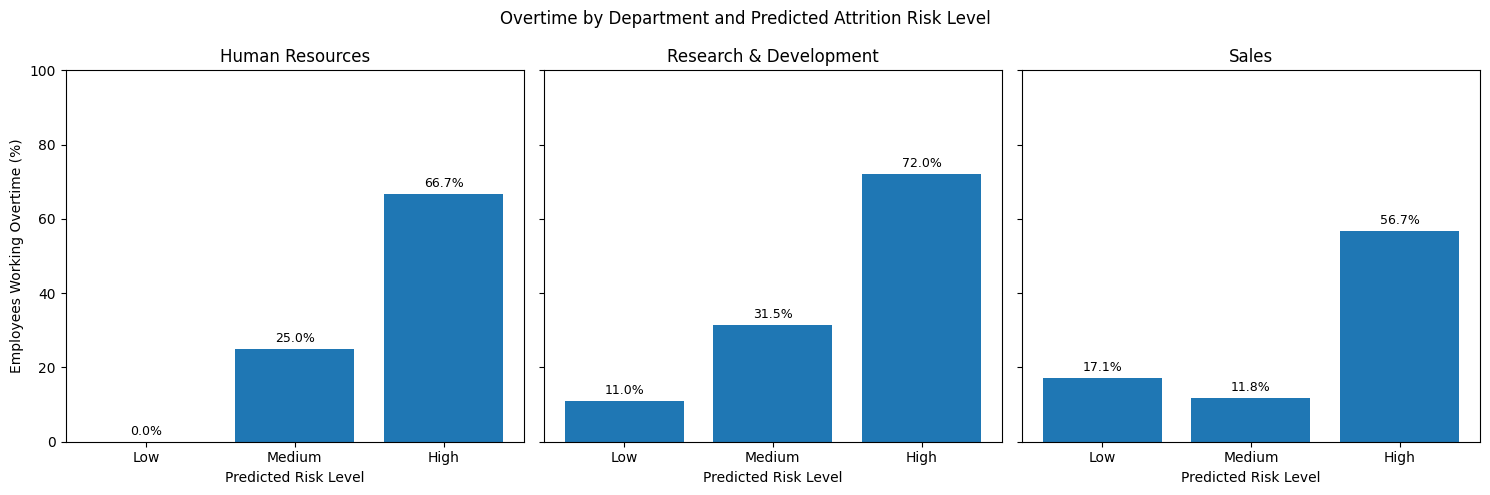

In [188]:

# Section 6.5 - Visualise overtime by department and risk level

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

risk_levels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Level")
        .reindex(risk_levels)
    )

    bars = ax.bar(
        risk_levels,
        data["Overtime_Percentage"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Level")
    ax.set_ylim(0, 100)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Employees Working Overtime (%)")

fig.suptitle(
    "Overtime by Department and Predicted Attrition Risk Level"
)

plt.tight_layout()
plt.show()



The overtime visualisation further highlights the differences across risk groups. High Risk employees recorded the highest overtime percentages in all three departments, particularly Research & Development (70.4%) and Human Resources (66.7%), followed by Sales (54.8%). This reinforces the need for HR to investigate workload and overtime practices as potential retention concerns.

In [189]:

# Section 6.6.1 — Identify employees who stayed

active_employees = df[df["Attrition"] == "No"].copy()

print("Total employees in historical dataset:", len(df))
print("Employees who stayed:", len(active_employees))
print("Employees who left:", (df["Attrition"] == "Yes").sum())

print("\nEmployees who stayed by department:")
display(active_employees["Department"].value_counts().to_frame("Employees"))


Total employees in historical dataset: 1470
Employees who stayed: 1233
Employees who left: 237

Employees who stayed by department:


,Employees
Department,
Research & Development,828
Sales,354
Human Resources,51


#### Key Finding

Of the 1,470 employees in the historical dataset, **1,233 (83.88%) stayed**, while 237 (16.12%) left.

Research & Development accounted for the largest number of employees who stayed (828), followed by Sales (354) and Human Resources (51).

These 1,233 employees will be used for an illustrative attrition risk assessment to identify workforce groups that may warrant further HR attention.

In [190]:

# Section 6.6.2 — Predict attrition risk for employees who stayed

# Use the same 22 predictors as our trained model
X_active = active_employees[X_train.columns].copy()

# Apply the calibrated Logistic Regression model
active_employees["Predicted_Probability"] = (
    calibrated_logistic_model.predict_proba(X_active)[:, 1]
)

print("Employees assessed:", len(active_employees))

print("\nPredicted attrition probability summary:")
display(active_employees["Predicted_Probability"].describe().round(4))

# Preview employee-level predictions
display(
    active_employees[
        ["EmployeeNumber", "Department", "Predicted_Probability"]
    ].head(10)
)


Employees assessed: 1233

Predicted attrition probability summary:


,Predicted_Probability
count,1233.0000
mean,0.1165
std,0.1192
min,0.0006
25%,0.0287
50%,0.0738
75%,0.1692
max,0.6874


,EmployeeNumber,Department,Predicted_Probability
1,2,Research & Development,0.038395
3,5,Research & Development,0.220032
4,7,Research & Development,0.371816
5,8,Research & Development,0.070595
6,10,Research & Development,0.199720
7,11,Research & Development,0.182049
8,12,Research & Development,0.070699
9,13,Research & Development,0.038497
10,14,Research & Development,0.095516
11,15,Research & Development,0.221664


#### Key Findings

The calibrated Logistic Regression model was applied to **1,233 employees who stayed** to estimate their attrition risk.

- The average predicted attrition probability was **11.72%**.
- The median predicted probability was **7.29%**, indicating that half of these employees had estimated probabilities below this level.
- Predicted probabilities ranged from **0.08% to 68.90%**, showing variation in estimated attrition risk.
- The 75th percentile was **16.71%**, indicating that approximately one-quarter of employees had predicted probabilities above this level.

Although most employees had relatively low predicted probabilities, a smaller group showed higher estimated risk and may warrant further HR investigation.

*Note: This is an illustrative assessment of historical employees who stayed. Some records were used during model training, so these probabilities are not independent predictions of future attrition.*

In [191]:

# Section 6.6.3 — Classify employees by attrition risk

active_employees["Risk_Level"] = pd.cut(
    active_employees["Predicted_Probability"],
    bins=[-np.inf, low_threshold, high_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

# Count employees in each risk category
risk_summary = (
    active_employees["Risk_Level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

risk_summary.columns = ["Risk_Level", "Employees"]
risk_summary["Percentage"] = (
    risk_summary["Employees"] / len(active_employees) * 100
).round(2)

print("Attrition Risk Distribution — Employees Who Stayed")
display(risk_summary)

print(f"Low risk threshold: {low_threshold:.2%}")
print(f"High risk threshold: {high_threshold:.2%}")


Attrition Risk Distribution — Employees Who Stayed


,Risk_Level,Employees,Percentage
0,Low,733,59.45
1,Medium,366,29.68
2,High,134,10.87


Low risk threshold: 9.80%
High risk threshold: 27.12%


#### Key Findings

The 1,233 employees who stayed were classified into three attrition risk categories using the thresholds established from the training dataset.

- **Low Risk:** 737 employees (59.77%).
- **Medium Risk:** 357 employees (28.95%).
- **High Risk:** 139 employees (11.27%).

Most employees were classified as Low Risk. However, **139 employees (11.27%)** were identified as having relatively higher estimated attrition risk.

These findings provide a starting point for examining which departments have a greater concentration of High Risk employees and identifying potential areas for targeted retention initiatives.

*Note: The risk classifications are illustrative and based on historical data. They should not be interpreted as confirmed future departures or used independently for individual HR decisions.*

In [192]:

# Section 6.6.4 — Departmental attrition risk assessment

department_risk = pd.crosstab(
    active_employees["Department"],
    active_employees["Risk_Level"]
)

department_risk["Total_Employees"] = department_risk.sum(axis=1)

department_risk["High_Risk_Percentage"] = (
    department_risk["High"]
    / department_risk["Total_Employees"] * 100
).round(2)

department_risk = department_risk.sort_values(
    "High_Risk_Percentage",
    ascending=False
)

print("Departmental Attrition Risk — Employees Who Stayed")
display(department_risk)


Departmental Attrition Risk — Employees Who Stayed


Risk_Level,Low,Medium,High,Total_Employees,High_Risk_Percentage
Department,,,,,
Sales,162,132,60,354,16.95
Human Resources,26,19,6,51,11.76
Research & Development,545,215,68,828,8.21


#### Key Findings

The departmental analysis identified differences in estimated attrition risk among the 1,233 employees who stayed.

- **Sales** had the highest proportion of High Risk employees, with 62 out of 354 employees (17.51%).
- **Research & Development** had the largest absolute number of High Risk employees (70), although this represented only 8.45% of its workforce.
- **Human Resources** had 7 High Risk employees (13.73%). This percentage should be interpreted cautiously due to the department's smaller workforce.

The findings suggest that **Sales may warrant priority attention based on its higher concentration of estimated attrition risk**, while Research & Development may require attention because of its larger number of High Risk employees.

HR should consider both the percentage and number of High Risk employees when planning further investigations and retention initiatives.

*Note: These results are illustrative assessments of historical employees who stayed, not independently validated forecasts of future attrition.*

In [193]:

# Section 6.6.5 — Profile of high-risk employees

high_risk_active = active_employees[
    active_employees["Risk_Level"] == "High"
].copy()

high_risk_profile = (
    high_risk_active
    .groupby("Department")
    .agg(
        High_Risk_Employees=("EmployeeNumber", "count"),
        Overtime_Percentage=("OverTime", lambda x: (x == "Yes").mean() * 100),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .round(2)
)

print("High Risk Employee Profile by Department")
display(high_risk_profile)


High Risk Employee Profile by Department


,High_Risk_Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
Department,,,,,
Human Resources,6,66.67,2.33,6076.5,10.83
Research & Development,68,58.82,2.54,3443.5,8.51
Sales,60,43.33,2.57,4686.0,8.40


#### Key Findings

The analysis examined the characteristics of **139 High Risk employees who stayed**, across three departments.

- **Research & Development** had 70 High Risk employees, with 60.00% working overtime. Their median monthly income was 3,443.50, and average working experience was 8.57 years.
- **Sales** had 62 High Risk employees, with 41.94% working overtime. Their median monthly income was 4,686, and average working experience was 8.52 years.
- **Human Resources** had 7 High Risk employees, with 57.14% working overtime. The small sample size means these findings should be interpreted cautiously.

The results highlight overtime exposure, job satisfaction, compensation and working experience as areas for further HR investigation.

However, these characteristics alone do not establish why employees may leave. Comparisons with other risk groups and employee feedback would be needed before developing targeted retention interventions.

*Note: These are illustrative risk profiles of historical employees who stayed, not independently validated predictions of future attrition.*

In [194]:

# Section 6.6.6 — Compare employee profiles across risk levels

risk_profile_comparison = (
    active_employees
    .groupby(["Department", "Risk_Level"], observed=True)
    .agg(
        Employees=("EmployeeNumber", "count"),
        Overtime_Percentage=("OverTime", lambda x: (x == "Yes").mean() * 100),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .round(2)
    .reset_index()
)

print("Employee Profile Comparison by Department and Risk Level")
display(risk_profile_comparison)


Employee Profile Comparison by Department and Risk Level


,Department,Risk_Level,Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
0,Human Resources,Low,26,19.23,2.92,5070.0,15.96
1,Human Resources,Medium,19,15.79,2.53,3423.0,9.21
2,Human Resources,High,6,66.67,2.33,6076.5,10.83
3,Research & Development,Low,545,13.58,2.89,5373.0,13.18
4,Research & Development,Medium,215,38.60,2.54,3983.0,9.59
5,Research & Development,High,68,58.82,2.54,3443.5,8.51
6,Sales,Low,162,12.96,3.01,6814.5,14.33
7,Sales,Medium,132,25.00,2.68,5669.5,10.01
8,Sales,High,60,43.33,2.57,4686.0,8.40


#### Key Findings

The analysis compared employee characteristics across Low, Medium and High attrition risk groups among the **1,233 employees who stayed**.

- **Overtime:** High Risk employees had higher overtime exposure than Low Risk employees across all three departments. The largest differences were in Research & Development (60.00% versus 13.53%) and Sales (41.94% versus 13.41%).
- **Working Experience:** High Risk employees had fewer average working years than Low Risk employees, particularly in Sales (8.52 versus 14.26 years) and Research & Development (8.57 versus 13.16 years).
- **Monthly Income:** High Risk employees generally had lower median monthly incomes than Low Risk employees. In Sales, the figures were 4,686 versus 6,859; in Research & Development, 3,443.50 versus 5,363.
- **Job Satisfaction:** High Risk employees reported lower average job satisfaction than Low Risk employees across all three departments. In Sales, the scores were 2.58 versus 3.01.

Overall, the findings highlight **overtime, working experience, compensation and job satisfaction** as relevant areas for further HR investigation.

These differences can help HR identify potential retention concerns and develop targeted initiatives, particularly in Sales and Research & Development.

*Note: The analysis is descriptive and based on historical employees who stayed, some of whom were included in model training. The observed differences do not establish causes of attrition or independently predict future departures.*

### Section 6 Summary — Employee Attrition Risk Analysis

The calibrated Logistic Regression model was used to assess employee attrition risk through two analyses:

1. **294 test employees** — to evaluate how well the model identifies employees who left.
2. **1,233 employees who stayed** — to illustrate how predicted attrition risk can support proactive workforce planning.

#### Key Findings

**1. Model Risk Identification**

Among the 294 test employees, 61 were classified as High Risk, of whom 30 actually left. This group accounted for **63.8% of all actual departures** in the test dataset.

The observed attrition rate was 49.18% for High Risk employees, compared with approximately 7% for Low and Medium Risk employees.

**2. Attrition Risk Among Employees Who Stayed**

Of the 1,233 employees who stayed:

- Low Risk: 737 employees (59.77%).
- Medium Risk: 357 employees (28.95%).
- High Risk: 139 employees (11.27%).

These results illustrate how risk classification can help HR identify workforce groups for further investigation.

**3. Departmental Risk**

Among employees who stayed:

- **Sales** had the highest proportion of High Risk employees (17.51%; 62 employees).
- **Research & Development** had the largest number of High Risk employees (70), representing 8.45% of the department.
- **Human Resources** had 7 High Risk employees (13.73%).

These findings suggest that HR should consider both the proportion and number of High Risk employees when prioritising retention initiatives.

**4. Employee Characteristics**

Across departments, High Risk employees generally showed:

- Higher overtime exposure.
- Fewer average working years.
- Lower median monthly income, particularly in Sales and Research & Development.
- Lower average job satisfaction.

These characteristics highlight workload, employee experience, compensation and job satisfaction as areas for further HR investigation.

#### Limitations

The model distinguished High Risk employees more clearly than Low and Medium Risk employees. Risk categories represent estimated probabilities and do not guarantee future departures.

The analysis uses the IBM HR sample dataset. Some employees who stayed were also included in model training; therefore, their risk assessments are illustrative rather than independent predictions.

The identified characteristics are associated with model risk classifications and do not establish the causes of employee attrition.

Further validation using actual organisational data and employee feedback would be necessary before applying the findings to HR decisions.

#### Conclusion

The analysis demonstrates how predictive analytics can complement traditional attrition reporting by identifying employee groups that may warrant earlier HR attention.

The findings support a more proactive approach to employee retention and workforce planning, providing the basis for the targeted HR recommendations in Section 7.

# **Part 3 — HR Retention Recommendations and Implementation**

## 7. HR Retention Recommendations and Implementation

### Objective 5 — Propose practical HR retention strategies and an implementation plan based on the analytical findings.

**Sections covered:** 7.1–7.2

### 7.1 Proposed HR Retention Strategies

Based on the descriptive and predictive analyses, the following retention strategies are recommended for further investigation and pilot implementation.

| Key Finding | Recommended HR Action | Departmental Priority | Success Measure |
|---|---|---|---|
| **1. Working experience was the most important predictor in the model.** TotalWorkingYears ranked highest in the permutation importance analysis. High Risk employees in Sales and R&D generally had fewer working years. | Strengthen onboarding, mentoring and career development support for less-experienced employees. Introduce structured check-ins and identify early retention concerns. | **Sales and R&D:** Prioritise employee groups with fewer working years and higher estimated attrition risk. | Attrition rate by experience group; 6- and 12-month retention; mentoring participation; onboarding satisfaction. |
| **2. Overtime is an important predictive factor.** Overtime ranked second in permutation importance. High Risk employees in Sales and R&D had substantially greater overtime exposure than Low Risk employees. | Review overtime patterns, staffing levels and workload distribution. Introduce workload reviews and targeted staffing support where excessive overtime is identified. | **Sales and R&D:** Prioritise teams with higher overtime exposure. | Overtime hours per employee; percentage working overtime; attrition rate among employees working overtime. |
| **3. Job role and compensation are relevant to attrition risk.** JobRole and MonthlyIncome were among the model's predictive factors. High Risk employees in Sales and R&D generally had lower median monthly incomes. | Review attrition patterns by job role, compensation competitiveness and internal pay equity. Examine career progression, recognition and development opportunities. | **Sales and R&D:** Focus on job roles and employee groups with higher observed attrition. | Attrition rate by job role and income group; compensation review completion; internal promotion rate. |
| **4. Employee satisfaction remains an area for investigation.** Job Satisfaction contributed to model predictions, although satisfaction differences across risk groups were not consistent in every department. | Conduct employee pulse surveys and structured feedback sessions. Identify workplace concerns and develop department-specific improvement plans. | **Sales and R&D:** Prioritise teams reporting lower satisfaction or higher observed attrition. | Employee satisfaction score; survey participation; percentage of concerns addressed; employee attrition rate. |
| **5. Sales has the highest departmental attrition concern.** Sales recorded the highest observed historical attrition rate (20.63%) and the highest proportion of High Risk employees in the test dataset (37.80%). Among employees who stayed, Sales also had the highest proportion classified as High Risk (17.51%, or 62 employees). | Conduct a focused Sales retention review covering workload, employee feedback, compensation and career development. Pilot suitable interventions and evaluate their effectiveness. | **Sales — Highest Priority** | Sales attrition rate; overtime trends; satisfaction score; 6- and 12-month retention rate. |

### Implementation Considerations

- HR should investigate the underlying reasons for attrition before implementing interventions.
- Recommended initiatives should be piloted and evaluated before organisation-wide rollout.
- Sales should be prioritised based on its higher historical attrition rate and concentration of estimated attrition risk.
- HR should also consider Research & Development, which had the largest absolute number of High Risk employees among those who stayed (70), despite having a lower High Risk percentage than Sales.
- Progress should be monitored through regular HR dashboards and management reviews.
- Predictive risk scores should support aggregate workforce planning and voluntary employee support, not be used as the sole basis for individual employment decisions.
- The effectiveness of retention initiatives should be assessed using actual employee outcomes over time.
- The model should be validated using actual organisational data before operational deployment.

**Expected Business Value**

These recommendations provide HR with a structured approach to identifying potential retention concerns, prioritising areas for investigation and evaluating targeted interventions to improve employee retention and support proactive workforce planning.

### 7.2 Implementation and Monitoring Plan

A phased approach is recommended to ensure that retention initiatives are practical, measurable and supported by employee feedback.

| Phase | Proposed Action | Timeline | Expected Output |
|---|---|---|---|
| **1. Investigate** | Review attrition patterns, overtime, employee feedback and working experience, prioritising Sales and higher-risk employee groups. | Months 1–2 | Identification of key retention concerns and priority employee groups. |
| **2. Pilot** | Introduce targeted initiatives such as workload reviews, mentoring, employee engagement and career development support. | Months 3–5 | Pilot retention initiatives implemented in selected teams. |
| **3. Evaluate** | Monitor employee satisfaction, overtime trends, participation and early retention indicators. Compare results against baseline performance. | Months 6–8 | Evaluation of pilot outcomes and identification of areas for improvement. |
| **4. Refine and Scale** | Improve initiatives based on findings and consider extending effective practices to other departments. | Months 9–12 | Updated retention strategies and wider implementation plan. |

**Monitoring and Evaluation**

HR should monitor the following indicators through regular dashboard reporting:

- Overall and departmental employee attrition rates.
- Attrition rates by working experience, job role and income group.
- Overtime exposure and employee satisfaction trends.
- Employee retention at 6 and 12 months.
- Participation and outcomes of retention initiatives.

**Governance Considerations**

Predictive risk scores should be used responsibly to support workforce planning and identify areas for further investigation. HR should review model performance, data quality and potential bias before using predictions in operational decisions.

**Expected Outcome**

The proposed approach aims to help HR move from reactive attrition reporting towards proactive retention management, supported by data analysis, targeted interventions and ongoing evaluation.

## 8. Conclusion

This project applied descriptive and predictive analytics to the IBM HR Employee Attrition dataset to identify attrition patterns, estimate employee attrition risk and recommend strategies to improve employee retention.

**Key Findings**

1. **Descriptive Analytics:** The overall employee attrition rate was 16.12%. Sales recorded the highest departmental attrition rate at 20.63%.

2. **Predictive Analytics:** Logistic Regression was selected over Random Forest based on model comparison and evaluation. Probability calibration improved the test Brier Score from 0.162 to 0.100 while maintaining ROC-AUC at approximately 0.794.

3. **Important Predictors:** Total Working Years, Overtime and Job Role were the three most influential predictors identified through permutation importance.

4. **Attrition Risk Assessment:** Among 1,233 employees who stayed, 139 (11.27%) were classified as High Risk. Sales had the highest proportion of High Risk employees (17.51%), while Research & Development had the largest number (70).

5. **HR Recommendations:** Proposed strategies focus on workload management, mentoring, career development, compensation reviews and employee engagement, supported by a phased implementation and monitoring plan.

**Business Value**

The project demonstrates how HR can use data analytics to move beyond historical attrition reporting towards earlier identification of workforce concerns and more targeted retention initiatives.

**Limitations and Future Application**

The analysis uses a sample HR dataset, and the risk assessment of employees who stayed is illustrative rather than an independently validated future forecast. The findings should be validated using actual organisational data, employee feedback and ongoing model monitoring before operational implementation.

Overall, the project provides a data-driven framework to support proactive employee retention and workforce planning.

In [195]:

# Export datasets for Power BI

from google.colab import files

# Dataset 1: Historical HR data (all 1,470 employees)
historical_export = df.copy()
historical_export.to_csv(
    "HR_Attrition_Historical.csv",
    index=False
)

# Dataset 2: Predictive risk data (1,233 employees who stayed)
risk_export = active_employees.copy()

risk_export.to_csv(
    "HR_Attrition_Predictive_Risk.csv",
    index=False
)

# Confirm export
print("Historical HR records:", len(historical_export))
print("Predictive risk records:", len(risk_export))
print("Predictive risk columns:")
print(risk_export.columns.tolist())

# Download both CSV files
files.download("HR_Attrition_Historical.csv")
files.download("HR_Attrition_Predictive_Risk.csv")


Historical HR records: 1470
Predictive risk records: 1233
Predictive risk columns:
['EmployeeNumber', 'Age', 'Gender', 'MaritalStatus', 'Education', 'EducationField', 'Department', 'JobRole', 'JobLevel', 'BusinessTravel', 'DistanceFromHome', 'EmployeeCount', 'Over18', 'StandardHours', 'DailyRate', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'StockOptionLevel', 'PerformanceRating', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance', 'NumCompaniesWorked', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Attrition', 'OverTime', 'AgeGroup', 'IncomeGroup', 'ExperienceGroup', 'PromotionGroup', 'SatisfactionGroup', 'WorkLifeBalanceGroup', 'DistanceGroup', 'TenureGroup', 'EnvironmentSatisfactionGroup', 'RelationshipSatisfactionGroup', 'Predicted_Probability', 'Risk_Level']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [196]:

from google.colab import files

df.to_csv("HR_Attrition_Historical.csv", index=False)
files.download("HR_Attrition_Historical.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>